# 01 · Entendimento do Negócio e dos Dados
**WishLens: Point. Snap. Want.** · Projeto final de Ciência de Dados I · Fases 1 e 2 do CRISP-DM

> ⚠️ **Dados fictícios.** Enquanto a coleta real não termina, este notebook usa
> `data/processed/desejos_demo.csv`, gerado por `src/exemplo.py`: 12 pessoas inventadas a partir de
> 4 estilos de desejo (gastronômico, tech, moda, pet), mais o perfil de exemplo "você".
> **Para usar os dados reais:** baixe o CSV anonimizado no app (*Meus Desejos → Baixar CSV anonimizado*),
> salve como `data/processed/desejos.csv` e troque `ARQUIVO` na célula abaixo. O resto roda igual.

## 1. Entendimento do negócio

**Problema.** No dia a dia vemos coisas que desejamos (uma roupa, um prato, um cachorro) e não temos um lugar único
para descobrir onde conseguir isso, nem para entender os nossos próprios padrões de desejo.

**Solução proposta.** Um app em que a pessoa fotografa qualquer coisa e recebe onde comprar (lojas próximas e online),
como fazer (receitas, restaurantes, delivery) ou onde adotar. Cada foto vira um **registro de desejo**.

**Perguntas que os dados devem responder**
1. O que as pessoas mais desejam: comprar, comer ou adotar? Quais categorias?
2. **Quando** elas desejam (dia da semana, hora)?
3. Existem **perfis de desejo** (grupos de pessoas parecidas)? → clustering (notebook 03)
4. O quanto duas pessoas combinam? → similaridade do cosseno (notebook 03)

**Critérios de sucesso**
- Perfis com significado claro (dá para dar um nome a cada grupo) e silhueta > 0,25.
- O reconhecimento acerta o item em pelo menos 70% de uma amostra rotulada à mão (avaliado no notebook 04).
- Nenhum dado pessoal identificável no CSV usado na análise.

## 2. Entendimento dos dados

| Fonte | Conteúdo | Licença |
|---|---|---|
| App WishLens (coleta própria, com consentimento) | um registro por foto: item, categoria, tipo, data/hora, cidade, confiança | uso no projeto, anonimizado |
| Catálogo `src/categorias.py` | 52 itens → 12 categorias → 3 tipos e faixa de preço de referência | próprio |
| OpenStreetMap | lugares próximos (não entra nesta análise) | ODbL |

O dicionário completo das colunas está em `docs/DICIONARIO_DE_DADOS.md`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # para importar src/

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette=["#6D4AFF", "#E8701F", "#17975F", "#C13B7A", "#2A7AB8", "#8C8A9E"])
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 2)

In [2]:
ARQUIVO = Path.cwd().parent / "data" / "processed" / "desejos_demo.csv"
df = pd.read_csv(ARQUIVO, parse_dates=["criado_em"])
print(f"{len(df)} desejos de {df['usuario'].nunique()} pessoas")
df.head()

361 desejos de 13 pessoas


,usuario,criado_em,item,categoria,tipo,faixa_preco,confianca,cidade,acao
0,exemplo:ana,2026-10-17 12:04:00,macarrão,comida,receita,R$ 15–80,0.87,Vitória - ES,ver_mapa
1,exemplo:ana,2026-10-19 15:58:00,café,bebidas,receita,R$ 5–60,0.42,Vitória - ES,ver_mapa
2,exemplo:ana,2026-10-19 20:55:00,arroz e feijão,comida,receita,R$ 15–80,0.80,Vitória - ES,ver_loja_online
3,exemplo:ana,2026-10-20 09:43:00,café,bebidas,receita,R$ 5–60,0.82,Vitória - ES,ver_receita
4,exemplo:ana,2026-10-20 10:45:00,café,bebidas,receita,R$ 5–60,0.49,Vitória - ES,salvou


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 361 entries, 0 to 360
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   usuario      361 non-null    str           
 1   criado_em    361 non-null    datetime64[us]
 2   item         361 non-null    str           
 3   categoria    361 non-null    str           
 4   tipo         361 non-null    str           
 5   faixa_preco  361 non-null    str           
 6   confianca    361 non-null    float64       
 7   cidade       361 non-null    str           
 8   acao         361 non-null    str           
dtypes: datetime64[us](1), float64(1), str(7)
memory usage: 51.4 KB


### Variáveis numéricas derivadas
O `describe()` só resume colunas numéricas. Além da `confianca` do reconhecimento, criamos:
- `hora` e `dia_semana` (0 = segunda) a partir de `criado_em`;
- `preco_min` e `preco_max` a partir da faixa de preço de referência (adoção = 0).

In [4]:
faixa = df["faixa_preco"].str.replace("R$", "", regex=False).str.replace(".", "", regex=False)
df["preco_min"] = pd.to_numeric(faixa.str.extract(r"(\d+)")[0], errors="coerce").fillna(0)
df["preco_max"] = pd.to_numeric(faixa.str.extract(r"–\s*(\d+)")[0], errors="coerce")
df["hora"] = df["criado_em"].dt.hour
df["dia_semana"] = df["criado_em"].dt.dayofweek
df[["confianca", "hora", "dia_semana", "preco_min", "preco_max"]].describe()

,confianca,hora,dia_semana,preco_min,preco_max
count,361.00,361.00,361.00,361.00,293.00
mean,0.67,13.91,2.91,95.71,1424.44
std,0.16,4.13,1.98,186.63,1818.74
min,0.40,7.00,0.00,0.00,60.00
25%,0.53,11.00,1.00,15.00,80.00
50%,0.66,14.00,3.00,50.00,300.00
75%,0.81,17.00,5.00,50.00,3000.00
max,0.95,21.00,6.00,1000.00,5000.00


### Lendo o `describe()`
- **count**: quantos valores não nulos. Se for menor que o total de linhas, há dados ausentes
  (`preco_max` é nulo para adoção e para "R$ 1.000+", que não têm teto).
- **mean × 50% (mediana)**: se forem muito diferentes, a distribuição é assimétrica ou tem outliers.
  Em `preco_max`, a média fica bem acima da mediana porque poucos eletrônicos caros puxam a média para cima.
- **std**: dispersão. Um desvio padrão alto em relação à média indica valores muito espalhados.
- **min / 25% / 75% / max**: os quartis mostram onde está a metade central dos dados.
  Em `hora`, 50% dos desejos acontecem entre o 1º e o 3º quartil.
- **confianca**: se o mínimo for baixo, há fotos que o modelo reconheceu mal. Isso vira regra de limpeza no notebook 02.

In [5]:
df[["usuario", "item", "categoria", "tipo", "faixa_preco", "cidade", "acao"]].describe()

,usuario,item,categoria,tipo,faixa_preco,cidade,acao
count,361,361,361,361,361,361,361
unique,13,51,12,3,12,1,4
top,exemplo:bruno,brinquedo,comida,comprar,R$ 15–80,Vitória - ES,ver_receita
freq,36,20,60,218,60,361,100


In [6]:
nulos = df.isna().sum()
nulos[nulos > 0]

preco_max    68
dtype: int64

## Distribuições

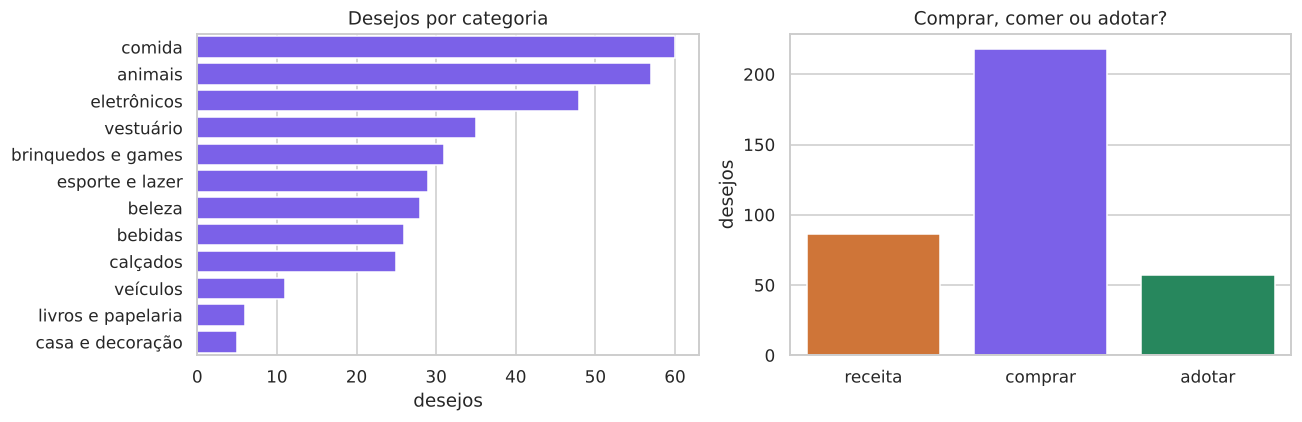

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ordem = df["categoria"].value_counts().index
sns.countplot(data=df, y="categoria", order=ordem, ax=ax[0], color="#6D4AFF")
ax[0].set(title="Desejos por categoria", xlabel="desejos", ylabel="")
sns.countplot(data=df, x="tipo", ax=ax[1], hue="tipo", legend=False,
              palette={"comprar": "#6D4AFF", "receita": "#E8701F", "adotar": "#17975F"})
ax[1].set(title="Comprar, comer ou adotar?", xlabel="", ylabel="desejos")
plt.tight_layout()

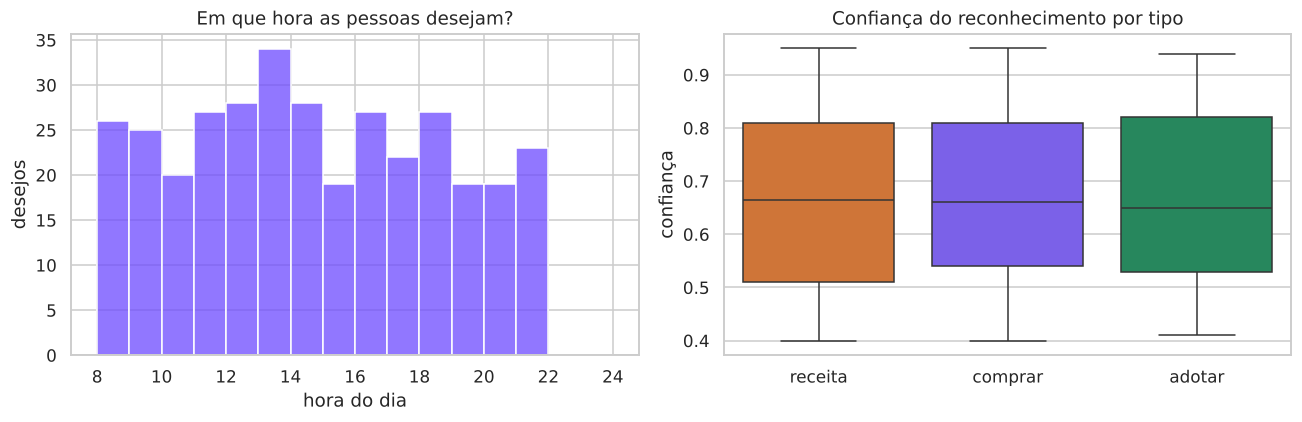

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="hora", bins=range(8, 25), ax=ax[0], color="#6D4AFF")
ax[0].set(title="Em que hora as pessoas desejam?", xlabel="hora do dia", ylabel="desejos")
sns.boxplot(data=df, x="tipo", y="confianca", ax=ax[1], hue="tipo", legend=False,
            palette={"comprar": "#6D4AFF", "receita": "#E8701F", "adotar": "#17975F"})
ax[1].set(title="Confiança do reconhecimento por tipo", xlabel="", ylabel="confiança")
plt.tight_layout()

Text(126.88460286458334, 0.5, '')

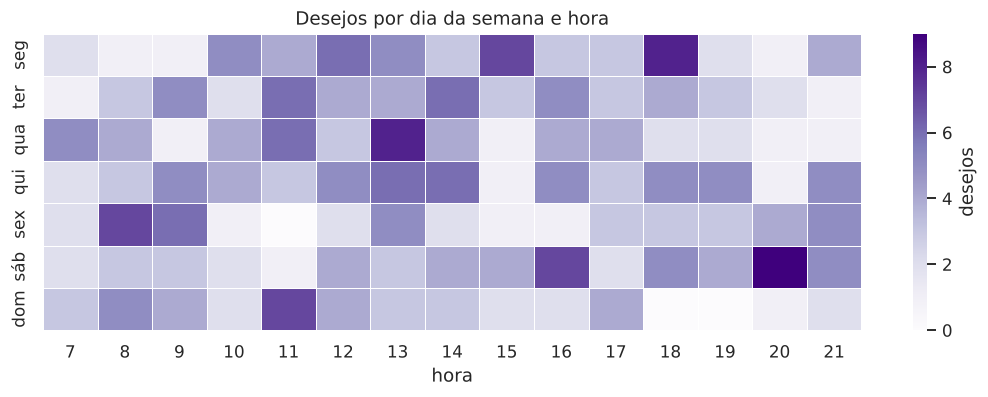

In [9]:
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
mapa = df.pivot_table(index="dia_semana", columns="hora", values="item", aggfunc="count", fill_value=0)
mapa.index = [dias[i] for i in mapa.index]
plt.figure(figsize=(12, 3.5))
sns.heatmap(mapa, cmap="Purples", linewidths=.5, cbar_kws={"label": "desejos"})
plt.title("Desejos por dia da semana e hora"); plt.xlabel("hora"); plt.ylabel("")

## Relações entre pessoas e categorias

Text(127.55647786458331, 0.5, '')

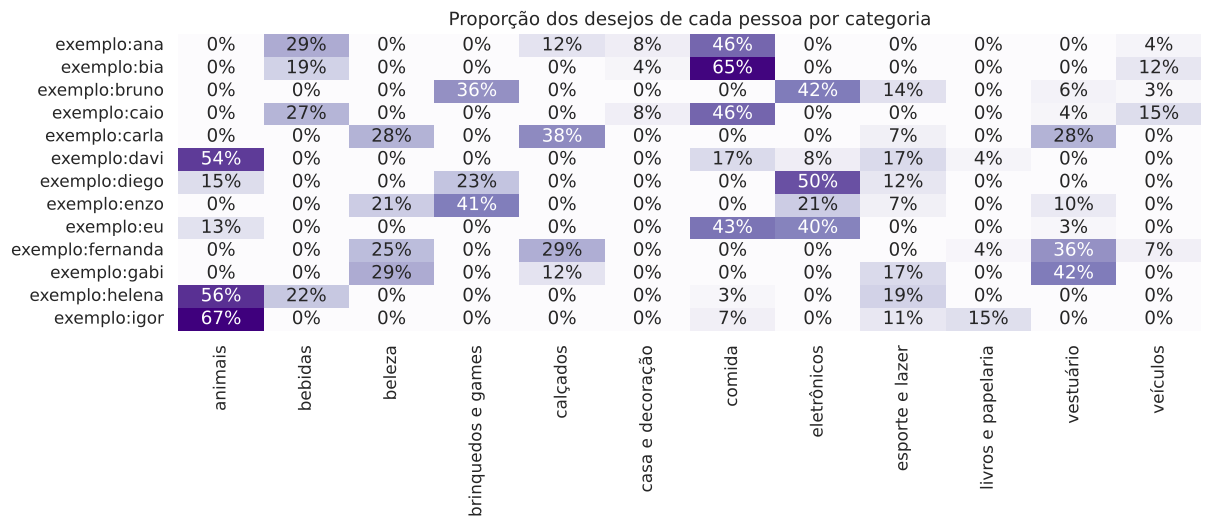

In [10]:
tabela = pd.crosstab(df["usuario"], df["categoria"], normalize="index")
plt.figure(figsize=(12, 3.5))
sns.heatmap(tabela, cmap="Purples", annot=True, fmt=".0%", cbar=False)
plt.title("Proporção dos desejos de cada pessoa por categoria"); plt.xlabel(""); plt.ylabel("")

Text(0.5, 1.0, 'Correlação entre variáveis numéricas')

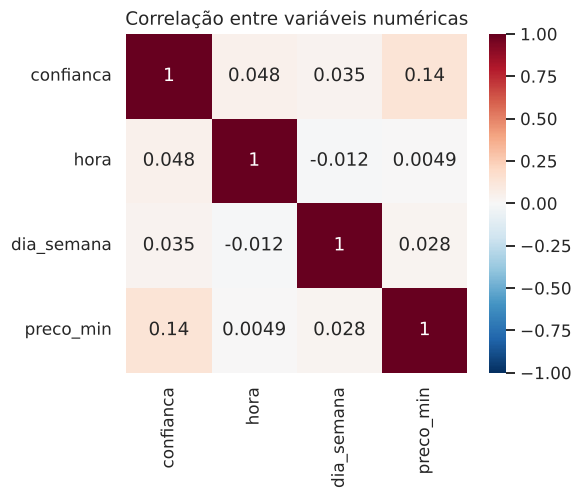

In [11]:
corr = df[["confianca", "hora", "dia_semana", "preco_min"]].corr()
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis numéricas")

## Conclusões do entendimento
- A tabela "pessoa × categoria" já mostra pessoas com gostos bem diferentes. Isso sugere que o **clustering**
  pode encontrar perfis (notebook 03).
- As variáveis numéricas quase não se correlacionam: o que diferencia as pessoas é **o que** elas desejam,
  não o horário ou a confiança. Por isso o vetor de perfil usa a **proporção por categoria**.
- Há desejos com confiança baixa: eles serão filtrados na preparação (notebook 02).
- *Lembrete:* estas conclusões valem para os dados fictícios; refaça a leitura com os dados reais.